# SpOTr on a toy tumor

SpOTr maps dissociated cancer cells to the spots of spatial transcriptomics data with their lineage tree. SpOTr is designed for tumors whose clones are hard to distinguish by their expression but occupy separate regions of the tissue, where closely related cells are more likely to be close in space.

We simulate such a tumor with `spotr.datasets.toy_tumor()`, map its dissociated cells with SpOTr, and compare the result with SpOTr without the tree.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scanpy as sc
import spotr
from spotr.plotting import spots, cells

## A toy tumor

The lineage is a Yule tree over the tumor cells, and each clade of the tree occupies a contiguous territory within that of its parent. The expression of the clones differs only weakly, through heritable programs that evolve along the tree. We measure one half of the tissue with Visium-like spots, sequence a fraction of the other half as dissociated cells, and read the lineage of some of these cells.

In [2]:
sc_adata, st_adata, tree, truth = spotr.datasets.toy_tumor(seed=0)
print(sc_adata)
print(st_adata)
sc_adata.obs["clone"].value_counts(dropna=False)

AnnData object with n_obs × n_vars = 1351 × 300
    obs: 'cell_type', 'clone'
    obsm: 'spatial_true'
AnnData object with n_obs × n_vars = 195 × 300
    obsm: 'spatial'


clone
NaN        845
clone 1    199
clone 2    151
clone 3     83
clone 4     41
clone 5     32
Name: count, dtype: int64

We show a UMAP of the dissociated cells, in which the clones overlap while the non-tumor cell types are separated.

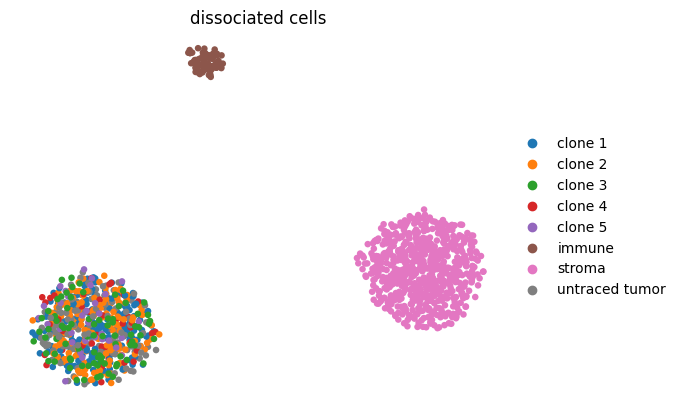

In [3]:
label = sc_adata.obs["clone"].astype(object).where(sc_adata.obs["clone"].notna(), sc_adata.obs["cell_type"].astype(str))
label = label.where(~((sc_adata.obs["cell_type"] == "tumor") & sc_adata.obs["clone"].isna()), "untraced tumor")
a = sc_adata.copy(); a.obs["label"] = pd.Categorical(label)
sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a); sc.pp.pca(a, n_comps=30); sc.pp.neighbors(a); sc.tl.umap(a)
sc.pl.umap(a, color="label", frameon=False, title="dissociated cells")

We show the spots of the measured half, colored as non-tumor where non-tumor cells outnumber tumor cells and otherwise by the majority clone. Each clone occupies its own territory.

<Axes: title={'center': 'truth'}>

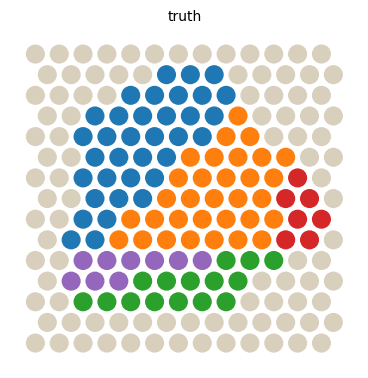

In [4]:
clones = [c for c in truth["clone_counts"].columns if c.startswith("clone")]
palette = dict(zip(clones, plt.get_cmap("tab10").colors)); NONTUMOR = "#d8cfbd"
def spot_colors(clone_mass, nontumor, tumor):
    """two levels: non-tumor where non-tumor cells outnumber tumor cells, else the majority clone"""
    return [NONTUMOR if n >= t else palette[clone_mass.columns[np.argmax(r)]] for r, n, t in zip(clone_mass.to_numpy(), nontumor, tumor)]
T = truth["clone_counts"]; xy = st_adata.obsm["spatial"]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
spots(ax, xy, spot_colors(T[clones], T[["stroma", "immune"]].sum(1), T[clones + ["smaller clones"]].sum(1)), "truth", shape="circle", pitch=80)

## SpOTr

`setup_anndata` registers the cell type of every cell, the clone of each cancer cell and the tree over the traced cells, given as a Newick string whose leaves are named by `obs_names`. SpOTr then fits the spot deconvolution and the mapping of the traced cells jointly.

In [5]:
spotr.SpOTr.setup_anndata(sc_adata, labels_key="cell_type", clone_key="clone", tree=tree)
model = spotr.SpOTr(sc_adata, st_adata).train(alpha=0.2)
model.get_proportions().head().round(3)

,immune,stroma,tumor,clone 1,clone 2,clone 3,clone 4,clone 5
spot0,0.000,0.991,0.004,0.002,0.0,0.000,0.003,0.0
spot1,0.000,1.000,0.000,0.000,0.0,0.000,0.000,0.0
spot2,0.000,1.000,0.000,0.000,0.0,0.000,0.000,0.0
spot3,0.000,0.999,0.000,0.000,0.0,0.000,0.000,0.0
spot4,0.007,0.989,0.002,0.000,0.0,0.002,0.000,0.0


For comparison, we fit the same model without the structural term (`alpha=0`), which maps the cells by their expression and the deconvolution of the spots alone.

In [6]:
no_tree = spotr.SpOTr(sc_adata, st_adata).train(alpha=0.0)

SpOTr               0.506223
without the tree    0.363523
dtype: float64

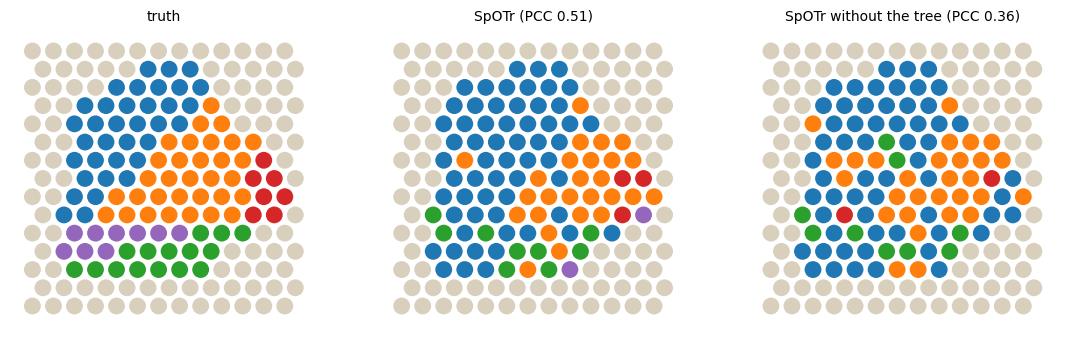

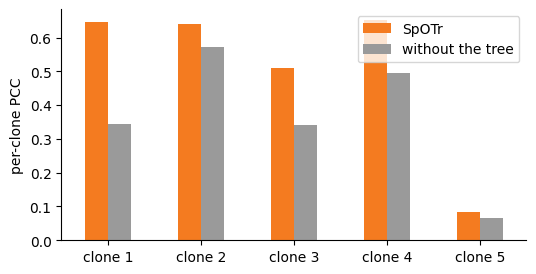

In [7]:
def per_clone_pcc(props):
    """the Pearson correlation between each clone's true and estimated share of the tumor cells across the spots that hold tumor cells"""
    true = T[clones].div(T[clones + ["smaller clones"]].sum(1).clip(lower=1), axis=0); est = props[clones].div(props[clones].sum(1).clip(lower=1e-12), axis=0)
    h = T[clones].sum(1) > 0
    return pd.Series({c: np.corrcoef(true.loc[h, c], est.loc[h, c])[0, 1] for c in clones})

fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.5))
spots(axs[0], xy, spot_colors(T[clones], T[["stroma", "immune"]].sum(1), T[clones + ["smaller clones"]].sum(1)), "truth", shape="circle", pitch=80)
for ax, (name, m) in zip(axs[1:], [("SpOTr", model), ("SpOTr without the tree", no_tree)]):
    P = m.get_proportions(); tum = P.drop(columns=["stroma", "immune"]).sum(1)          # every cancer cell, with a clone or without
    spots(ax, xy, spot_colors(P[clones], P[["stroma", "immune"]].sum(1), tum), f"{name} (PCC {per_clone_pcc(P).mean():.2f})", shape="circle", pitch=80)

scores = pd.DataFrame({"SpOTr": per_clone_pcc(model.get_proportions()), "without the tree": per_clone_pcc(no_tree.get_proportions())})
ax = scores.plot.bar(color=["#F47B20", "#9a9a9a"], figsize=(6, 3), rot=0); ax.set_ylabel("per-clone PCC"); ax.spines[["top", "right"]].set_visible(False)
scores.mean()

## Expected positions of the cells

We show the expected position of each traced cell under the mapping next to its true position in the tumor, since the dissociated cells come from the other half of the same tissue. The expected positions are averages over the spots to which a cell may be mapped, so they are closer to the center of each clone than the true positions.

<Axes: title={'center': 'SpOTr'}>

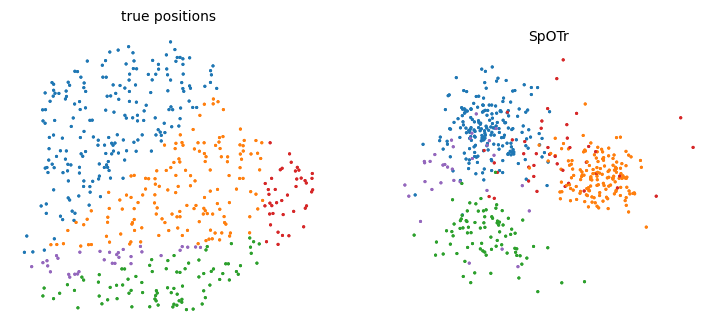

In [8]:
mapped = sc_adata.obs["clone"].notna().to_numpy(); col = [palette.get(c, "#bdbdbd") for c in sc_adata.obs["clone"][mapped]]
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
cells(axs[0], sc_adata.obsm["spatial_true"][mapped], col, "true positions", size=6)
cells(axs[1], sc_adata.obsm["spotr_spatial"][mapped], col, "SpOTr", size=6)

## Choosing alpha

The structural importance `alpha` sets the trade-off between the expression cost and the structural cost of the mapping. We choose `alpha` on new data at the elbow of this trade-off, where the sum of the two costs is smallest after normalizing each cost between the smallest and the largest `alpha`.

elbow: 0.4


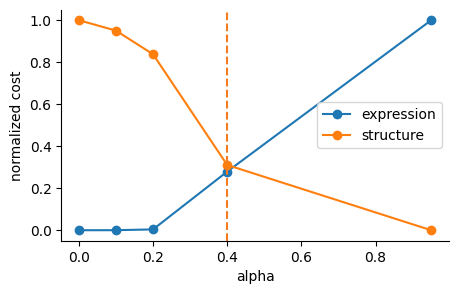

In [9]:
alpha, costs = model.choose_alpha([0.0, 0.1, 0.2, 0.4, 0.95])
ax = costs[["expression", "structure"]].apply(lambda v: (v - v.min()) / (v.max() - v.min())).plot(marker="o", figsize=(5, 3))
ax.axvline(alpha, color="#F47B20", ls="--"); ax.set_ylabel("normalized cost"); ax.spines[["top", "right"]].set_visible(False)
print("elbow:", alpha)